# 08 · Modelo final y respuesta a la pregunta
**Proyecto Integrador ML2 — Entrega final · Predicción de la TRM**

**Objetivo (rúbrica 8.1).** Elegir el modelo final **para responder la pregunta de investigación** de la Entrega 1:

> ¿La incorporación de variables macroeconómicas locales (petróleo, diferencial de tasas Banrep–Fed, fortaleza del dólar) mejora la predicción del precio diario de la TRM frente a un modelo que solo usa su comportamiento pasado, y cuál de los tres algoritmos de gradient boosting aprovecha mejor esa información?

En la Entrega 2 las diferencias entre modelos fueron de centavos frente a unos 7 pesos de variación entre periodos. Aquí se pasa de "empate a ojo" a **pruebas formales**, y con ellas se decide el modelo final.

**Reglas:**
1. **Todo se decide con la validación** (5 cortes walk-forward del desarrollo, 3.600 días). El test ya se abrió en la Entrega 2; en este notebook solo se usa para reportar (sección final).
2. **Pruebas:** Diebold-Mariano (¿tienen dos modelos el mismo error cuadrático medio?, con varianza Newey-West) y un intervalo bootstrap por bloques de 20 días de la diferencia de RMSE, remuestreando dentro de cada corte. Las dos usan el error de cada día en pesos.
3. **Regla del modelo final, fijada antes de calcular:** el modelo final es la configuración de boosting elegida por la regla congelada de la Entrega 2 (menor RMSE medio en validación), **siempre que no sea significativamente peor que la línea base** (Diebold-Mariano al 5 %). La línea base se reporta a su lado como referencia.
4. Las funciones de las pruebas están en `src/validacion.py` y se validaron con simulaciones (tamaño ≈ 5 %, también con errores autocorrelacionados).

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as cfg
from src.validacion import errores_en_pesos, prueba_diebold_mariano, bootstrap_bloques_diferencia_rmse
from src.graficos import estilo, guardar_figura, guardar_tabla, COLORES

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
congelada = json.loads(cfg.CONFIG_CONGELADA.read_text(encoding="utf-8"))
BASE, MEJOR = "Línea base (lineal)", congelada["mejor_boosting"]

trm = pd.read_csv(cfg.DATA_PROC / "dataset.csv", parse_dates=["fecha"])[["fecha", "trm", "muestra"]]
val = pd.read_csv(cfg.DATA_PROC / "predicciones_validacion.csv", parse_dates=["fecha"]).merge(trm, on="fecha", how="left")
assert val["trm"].notna().all() and (val["muestra"] == "desarrollo").all()      # solo desarrollo
val["error_pesos"] = errores_en_pesos(val["y"], val["yhat"], val["trm"])
E = val.pivot_table(index=["corte", "fecha"], columns="modelo", values="error_pesos")
CORTE = E.index.get_level_values("corte")
rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))
print(f"Días de validación: {len(E):,} ({E.index.get_level_values('fecha').min().date()} a "
      f"{E.index.get_level_values('fecha').max().date()}) · modelos: {E.shape[1]} · mejor congelado: {MEJOR}")

Días de validación: 3,600 (2006-12-23 a 2022-03-01) · modelos: 7 · mejor congelado: CatBoost · solo_trm


## 1. ¿Algún boosting predice mejor que la línea base?
Cada configuración de boosting frente a la regresión lineal sobre los rezagos de la TRM, con los 3.600 días juntos y corte por corte. Diferencia negativa = el boosting tiene menos error.

In [2]:
def comparar(a, b):
    '''Compara dos modelos en validación: los 5 cortes juntos (DM y bootstrap) y DM en cada corte.

    Parámetros
    ----------
    a, b : str
        Nombres de los modelos (columnas de E); la diferencia se calcula como a − b.

    Devuelve
    --------
    dict
        Diferencia de RMSE, intervalo bootstrap, probabilidad de que a sea mejor, estadístico y
        p-valor de Diebold-Mariano, y el p-valor de DM en cada corte.
    '''
    dm = prueba_diebold_mariano(E[a], E[b])
    bs = bootstrap_bloques_diferencia_rmse(E[a], E[b], grupos=CORTE)
    fila = {"delta_rmse": bs["diferencia_rmse"], "ic95_inf": bs["ic95_inf"], "ic95_sup": bs["ic95_sup"],
            "prob_mejor": bs["prob_e1_mejor"], "dm": dm["estadistico"], "p_valor": dm["p_valor"]}
    for c in range(1, 6):
        m = CORTE == c
        fila[f"delta_rmse_corte_{c}"] = rmse(E.loc[m, a]) - rmse(E.loc[m, b])
        fila[f"p_corte_{c}"] = prueba_diebold_mariano(E.loc[m, a], E.loc[m, b])["p_valor"]
    return fila

BOOSTING = [f"{alg} · {c}" for alg in cfg.MODELOS_BOOSTING for c in cfg.CONJUNTOS]
t11 = pd.DataFrame({m: comparar(m, BASE) for m in BOOSTING}).T
t11.insert(0, "rmse_conjunto", [rmse(E[m]) for m in BOOSTING])
t11["significativo_5pct"] = t11["p_valor"] < 0.05
t11["cortes_con_p_menor_5pct"] = (t11[[f"p_corte_{c}" for c in range(1, 6)]] < 0.05).sum(axis=1)
t11.index.name = "boosting_frente_a_linea_base"
guardar_tabla(t11, "tab11_boosting_vs_base")
print(f"Línea base: RMSE conjunto {rmse(E[BASE]):.3f} pesos")
display(t11[["rmse_conjunto", "delta_rmse", "ic95_inf", "ic95_sup", "prob_mejor", "dm", "p_valor",
             "significativo_5pct", "cortes_con_p_menor_5pct"]])

Línea base: RMSE conjunto 21.754 pesos


,rmse_conjunto,delta_rmse,ic95_inf,ic95_sup,prob_mejor,dm,p_valor,significativo_5pct,cortes_con_p_menor_5pct
boosting_frente_a_linea_base,,,,,,,,,
LightGBM · solo_trm,21.6570,-0.0973,-0.3690,0.1454,0.7170,-0.7503,0.4531,False,0
LightGBM · trm_macro,21.6595,-0.0947,-0.3620,0.1402,0.7235,-0.7446,0.4566,False,0
CatBoost · solo_trm,21.5968,-0.1574,-0.4895,0.1250,0.8180,-0.9965,0.3191,False,0
CatBoost · trm_macro,21.6382,-0.1161,-0.4498,0.1526,0.7750,-0.7943,0.4271,False,1
XGBoost · solo_trm,21.6877,-0.0666,-0.4568,0.2281,0.6375,-0.4013,0.6882,False,1
XGBoost · trm_macro,21.7925,0.0383,-0.3481,0.3764,0.3840,0.2274,0.8201,False,2


## 2. ¿Las variables macro mejoran a algún algoritmo?
Cada algoritmo con TRM + macro frente al mismo algoritmo con solo TRM (misma búsqueda, mismos cortes). Es la primera parte de la pregunta, ahora con prueba formal. Diferencia negativa = las macro bajan el error.

In [3]:
t11a = pd.DataFrame({alg: comparar(f"{alg} · trm_macro", f"{alg} · solo_trm") for alg in cfg.MODELOS_BOOSTING}).T
t11a["significativo_5pct"] = t11a["p_valor"] < 0.05
t11a["cortes_donde_macro_baja_rmse"] = (t11a[[f"delta_rmse_corte_{c}" for c in range(1, 6)]] < 0).sum(axis=1)
t11a.index.name = "macro_frente_a_solo_trm"
guardar_tabla(t11a, "tab11a_aporte_macro_formal")
display(t11a[["delta_rmse", "ic95_inf", "ic95_sup", "prob_mejor", "dm", "p_valor", "significativo_5pct",
              "cortes_donde_macro_baja_rmse"]])

,delta_rmse,ic95_inf,ic95_sup,prob_mejor,dm,p_valor,significativo_5pct,cortes_donde_macro_baja_rmse
macro_frente_a_solo_trm,,,,,,,,
LightGBM,0.0025,-0.0785,0.0756,0.5365,0.0644,0.9486,False,4
CatBoost,0.0413,-0.0752,0.1406,0.3035,0.7539,0.4509,False,2
XGBoost,0.1049,0.0053,0.2585,0.0215,1.5686,0.1168,False,1


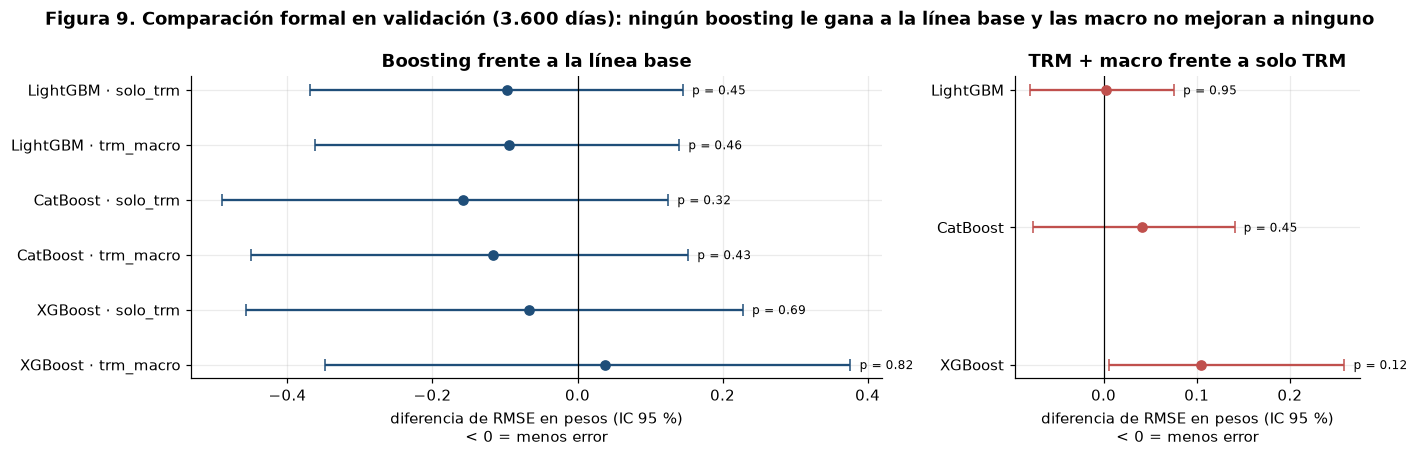

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [6, 3]})
for eje, tabla, titulo, color in [
        (ejes[0], t11, "Boosting frente a la línea base", COLORES[0]),
        (ejes[1], t11a, "TRM + macro frente a solo TRM", COLORES[1])]:
    y = np.arange(len(tabla))[::-1]
    eje.errorbar(tabla["delta_rmse"], y, xerr=[tabla["delta_rmse"] - tabla["ic95_inf"], tabla["ic95_sup"] - tabla["delta_rmse"]],
                 fmt="o", color=color, capsize=4)
    for yi, (_, f) in zip(y, tabla.iterrows()):
        eje.annotate(f"p = {f['p_valor']:.2f}", (f["ic95_sup"], yi), xytext=(6, -3), textcoords="offset points", fontsize=8)
    eje.axvline(0, color="k", lw=0.8)
    eje.set(yticks=y, yticklabels=tabla.index, title=titulo, xlabel="diferencia de RMSE en pesos (IC 95 %)\n< 0 = menos error")
fig.suptitle("Figura 9. Comparación formal en validación (3.600 días): ningún boosting le gana a la línea base y las macro no mejoran a ninguno",
             fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "fig09_comparacion_formal")
plt.show()

## 3. Modelo final según la regla

In [5]:
f = t11.loc[MEJOR]
peor_significativo = (f["delta_rmse"] > 0) and (f["p_valor"] < 0.05)
MODELO_FINAL = BASE if peor_significativo else MEJOR
decision = pd.Series({
    "mejor_boosting_regla_congelada": MEJOR,
    "delta_rmse_frente_a_base": f["delta_rmse"], "ic95": f"[{f['ic95_inf']:+.3f}; {f['ic95_sup']:+.3f}]",
    "p_valor_diebold_mariano": f["p_valor"], "significativamente_peor_que_base": peor_significativo,
    "modelo_final": MODELO_FINAL, "referencia": BASE,
}, name="decision")
guardar_tabla(decision.to_frame(), "tab11b_decision_modelo_final")
display(decision.to_frame())

,decision
mejor_boosting_regla_congelada,CatBoost · solo_trm
delta_rmse_frente_a_base,-0.1574
ic95,[-0.489; +0.125]
p_valor_diebold_mariano,0.3191
significativamente_peor_que_base,False
modelo_final,CatBoost · solo_trm
referencia,Línea base (lineal)


## Lectura y respuesta a la pregunta
**1. Ningún boosting predice mejor que la regresión lineal (Tabla 11, Figura 9).** Con los 3.600 días de validación juntos, las seis configuraciones tienen diferencias de −0,16 a +0,04 pesos frente a un RMSE de 21,75; Diebold-Mariano no rechaza en ninguna (p de 0,32 a 0,82) y todos los intervalos bootstrap contienen el cero. Corte por corte, de 30 comparaciones solo 4 son significativas al 5 %, y **las 4 favorecen a la línea base** (CatBoost con macro en el corte 3; XGBoost solo TRM en el 4; XGBoost con macro en el 2 y el 3). En ningún corte un boosting es significativamente mejor. (Con 30 pruebas al 5 % se esperan 1 o 2 rechazos por azar; los 4 apuntan en la misma dirección.)

**2. Las variables macro no mejoran a ningún algoritmo (Tabla 11a).** Con macro, el RMSE cambia +0,003 pesos en LightGBM, +0,04 en CatBoost y +0,10 en XGBoost: en los tres, **igual o peor**. Diebold-Mariano no rechaza en ninguno (p de 0,12 a 0,95). En XGBoost el intervalo bootstrap queda entero del lado de "peor" ([+0,005; +0,259]): las macro probablemente lo empeoran, aunque DM no lo confirma al 5 %. LightGBM es el que menos se perjudica (diferencia prácticamente cero; mejora en 4 de 5 cortes, por centavos).

**3. Respuesta a la pregunta de investigación.**
- **¿Mejoran las macro la predicción diaria de la TRM?** No. Con prueba formal, ninguna versión con petróleo, diferencial de tasas y DXY predice mejor que la misma sin ellas, ni mejor que la regresión lineal sobre la TRM.
- **¿Qué algoritmo las aprovecha mejor?** Ninguno las aprovecha. LightGBM es el que menos se perjudica; XGBoost, el que más.
- Ampliar la ventana de rezagos tampoco mejora (notebook 07).

**4. Modelo final: CatBoost · solo TRM (Tabla 11b).** Es el que eligió la regla congelada (menor RMSE medio en validación) y no es significativamente peor que la base (−0,16 pesos, IC [−0,49; +0,13], p = 0,32), así que la regla lo mantiene. **Lo que hay que decir con todas las letras:** está en empate estadístico con la regresión lineal; sale adelante en 4 de 5 cortes y en el 82 % de los remuestreos, pero por centavos. Ese empate no es un fracaso del modelo: es parte de la respuesta. Lo único predecible de la TRM a un día es la continuación del movimiento de hoy, que es casi lineal; el boosting lo aprende igual de bien y agrega muy poco. La regresión lineal se mantiene a su lado como referencia interpretable (mañana = hoy + ≈17 % del movimiento de hoy).

---
# Parte 2 · ¿Por qué no funcionó con la TRM? (rúbrica 8.1)
Dos explicaciones: **(a)** cuánta señal hay para predecir la TRM de mañana, y **(b)** por qué las macro, en vez de ayudar, a veces empeoran, con el caso del diferencial de tasas, que se dejó pendiente en el informe de la Entrega 2.

## 4. Cuánta señal hay
Resumen de evidencia que ya existe (EDA del notebook 03 y experimento del notebook 07), todo con el desarrollo.

In [6]:
T = lambda n, **kw: pd.read_csv(cfg.TABLAS / f"{n}.csv", **kw)
acf = T("tabE4_autocorrelacion", index_col=0)
techo = T("tabE9b_techo_lineal", index_col=0)["valor"]
corr = T("tabE5_correlaciones", index_col=0)
estab = T("tabE6_estabilidad", index_col=0)
mem = T("tab10d_memoria_por_volatilidad", index_col=0)
senal = pd.DataFrame([
    ["Memoria del movimiento a 1 día", f"{acf.loc[1, 'acf']:.3f}", "E4: única autocorrelación significativa"],
    ["Memoria a 2–20 días (máx. |valor|)", f"{acf.loc[2:20, 'acf'].abs().max():.3f}", "E4: dentro de la banda de ruido"],
    ["R² dentro de muestra, lineal solo TRM", f"{techo['R2_dentro_muestra_lineal_solo_TRM']:.3f}", "E9: techo de lo explicable"],
    ["R² dentro de muestra, lineal TRM + macro", f"{techo['R2_dentro_muestra_lineal_TRM_macro']:.3f}", "E9: las macro suman ≈ 0,003"],
    ["Correlación con mañana: DXY / Brent / diferencial",
     f"{corr.loc['r_dxy', 'pearson']:+.3f} / {corr.loc['r_brent', 'pearson']:+.3f} / {corr.loc['dif_tasas', 'pearson']:+.3f}", "E5: débiles"],
    ["Ventanas con el signo esperado: DXY / Brent", f"{estab.iloc[:, 0].get('r_dxy', np.nan):.0f} % / {estab.iloc[:, 0].get('r_brent', np.nan):.0f} %",
     "E6: la relación con el Brent cambia de signo en el tiempo"],
    ["Memoria a 1 día con volatilidad baja / alta", f"{mem['pearson'].iloc[0]:.3f} / {mem['pearson'].iloc[-1]:.3f}", "nb 07: cae en mercados agitados (p = 0,015)"],
], columns=["evidencia", "valor", "fuente y lectura"]).set_index("evidencia")
guardar_tabla(senal, "tab12_senal_disponible")
display(senal)

,valor,fuente y lectura
evidencia,,
Memoria del movimiento a 1 día,0.165,E4: única autocorrelación significativa
Memoria a 2–20 días (máx. |valor|),0.030,E4: dentro de la banda de ruido
"R² dentro de muestra, lineal solo TRM",0.028,E9: techo de lo explicable
"R² dentro de muestra, lineal TRM + macro",0.031,"E9: las macro suman ≈ 0,003"
Correlación con mañana: DXY / Brent / diferencial,+0.094 / -0.056 / +0.008,E5: débiles
Ventanas con el signo esperado: DXY / Brent,95 % / 64 %,E6: la relación con el Brent cambia de signo e...
Memoria a 1 día con volatilidad baja / alta,0.226 / 0.137,"nb 07: cae en mercados agitados (p = 0,015)"


## 5. El diferencial de tasas: un régimen que no se repitió
El diferencial es la TPM del Banco de la República menos la tasa de la Fed, en puntos porcentuales. En la Entrega 2, SHAP mostró que el modelo con macro le daba un 31 % de la importancia y que su efecto saltaba por encima de ~7,8 pp. Aquí se mira cuándo ocurrieron esos valores y qué hizo la TRM en cada caso. El test se usa **solo para describir**: el modelo ya está elegido.

In [7]:
import joblib
from src.validacion import cortes_walk_forward
from src.modelos import evaluar_walk_forward, ajustar_final, crear_modelo

datos = pd.read_csv(cfg.DATA_PROC / "dataset.csv", parse_dates=["fecha"])
dev = datos[datos["muestra"] == "desarrollo"].reset_index(drop=True)
test = datos[datos["muestra"] == "test"].reset_index(drop=True)
UMBRAL = 7.8
filas = []
for nombre, d in [("desarrollo (2003–2022)", dev), ("test (2022–2026)", test)]:
    alto = d[d["dif_tasas"] > UMBRAL]
    filas.append({"muestra": nombre, "dias": len(d), "dias_dif_mayor_7_8": len(alto),
                  "pct_dias": 100 * len(alto) / len(d),
                  "anios": ", ".join(str(a) for a in sorted(alto["fecha"].dt.year.unique())),
                  "movimiento_medio_manana_pb": 1e4 * alto["y"].mean(),
                  "dias_que_sube_pct": 100 * (alto["y"] > 0).mean(),
                  "dif_max_pp": d["dif_tasas"].max(), "dif_mediana_pp": d["dif_tasas"].median()})
regimen = pd.DataFrame(filas).set_index("muestra")
guardar_tabla(regimen, "tab12a_diferencial_por_regimen")
display(regimen)

,dias,dias_dif_mayor_7_8,pct_dias,anios,movimiento_medio_manana_pb,dias_que_sube_pct,dif_max_pp,dif_mediana_pp
muestra,,,,,,,,
desarrollo (2003–2022),4320,151,3.4954,"2008, 2009",33.0508,63.5762,9.8900,3.7000
test (2022–2026),1080,273,25.2778,"2022, 2023, 2026",-5.2370,45.0549,8.4200,6.6100


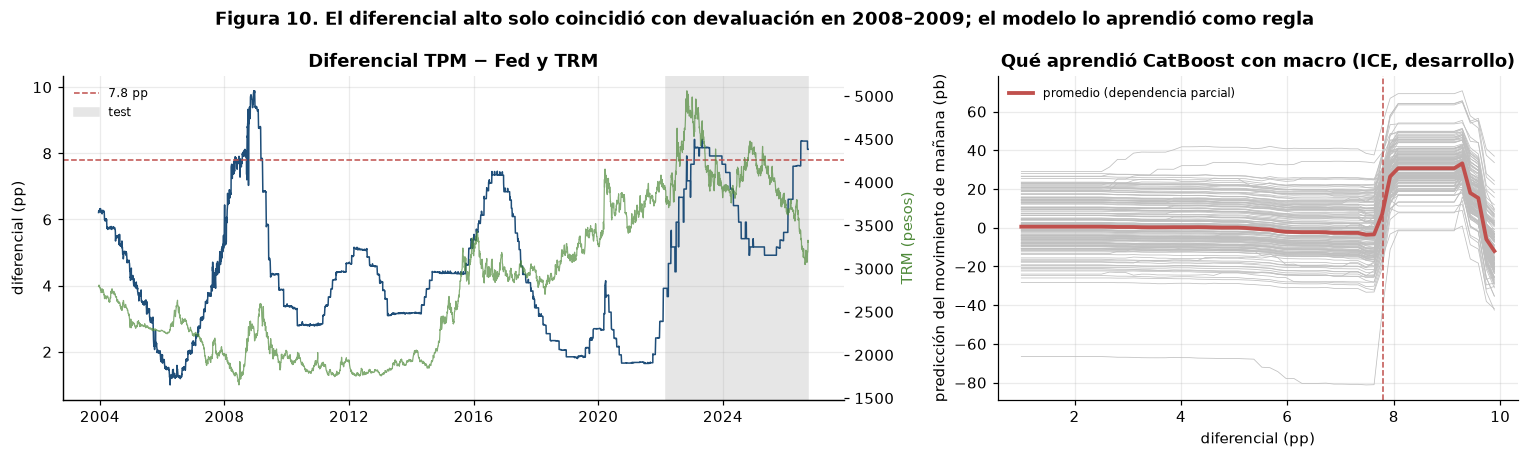

Salto medio de la predicción por encima de 7.8 pp: +23.1 pb por día


In [8]:
from sklearn.inspection import partial_dependence

modelos = joblib.load(cfg.MODELOS / "modelos_finales.joblib")
m_macro = modelos["CatBoost · trm_macro"]
X_dev = dev[cfg.VARS_TODAS]
pd_dif = partial_dependence(m_macro, X_dev, ["dif_tasas"], kind="both", grid_resolution=60,
                            percentiles=(0, 1))   # todo el rango: por defecto se queda en el p95 (< 7,8 pp)
grilla, promedio, individuales = pd_dif["grid_values"][0], pd_dif["average"][0], pd_dif["individual"][0]

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [3, 2]})
eje = ejes[0]
eje.plot(datos["fecha"], datos["dif_tasas"], color=COLORES[0], lw=1)
eje.axhline(UMBRAL, color=COLORES[1], ls="--", lw=1, label=f"{UMBRAL} pp")
eje.axvspan(test["fecha"].min(), test["fecha"].max(), color="0.9", label="test")
eje2 = eje.twinx(); eje2.plot(datos["fecha"], datos["trm"], color=COLORES[2], lw=0.8, alpha=0.7)
eje2.set_ylabel("TRM (pesos)", color=COLORES[2]); eje2.grid(False)
eje.set(title="Diferencial TPM − Fed y TRM", ylabel="diferencial (pp)"); eje.legend(loc="upper left", frameon=False, fontsize=8)
eje = ejes[1]
rng = np.random.default_rng(cfg.SEMILLA)
for i in rng.choice(len(individuales), 150, replace=False):
    eje.plot(grilla, 1e4 * individuales[i], color="0.75", lw=0.5)
eje.plot(grilla, 1e4 * promedio, color=COLORES[1], lw=2.5, label="promedio (dependencia parcial)")
eje.axvline(UMBRAL, color=COLORES[1], ls="--", lw=1)
eje.set(title="Qué aprendió CatBoost con macro (ICE, desarrollo)", xlabel="diferencial (pp)",
        ylabel="predicción del movimiento de mañana (pb)")
eje.legend(frameon=False, fontsize=8)
fig.suptitle("Figura 10. El diferencial alto solo coincidió con devaluación en 2008–2009; el modelo lo aprendió como regla",
             fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "fig10_diferencial_regimen")
plt.show()
salto = 1e4 * (promedio[grilla > UMBRAL].mean() - promedio[grilla < UMBRAL - 1].mean())
print(f"Salto medio de la predicción por encima de {UMBRAL} pp: {salto:+.1f} pb por día")

## 6. Sensibilidad: las macro sin el diferencial
Los tres boosting con TRM + Brent + DXY, **sin el diferencial**, con exactamente la misma validación anidada de la Entrega 2 (mismos cortes, misma búsqueda, solo desarrollo). Pregunta: ¿el diferencial es el que hace daño, o las macro no aportan aunque se quite? Después, como diagnóstico, cada versión se reentrena con todo el desarrollo y se mide en el test.

In [9]:
SIN_DIF = cfg.VARS_TRM + ["r_brent", "r_dxy"]
cortes = cortes_walk_forward(len(dev))
assert np.array_equal(np.sort(dev.loc[np.concatenate([va for _, va in cortes]), "fecha"].to_numpy()),
                      np.sort(E.index.get_level_values("fecha").unique().to_numpy()))    # mismos días que la Entrega 2
pt = pd.read_csv(cfg.DATA_PROC / "predicciones_test.csv", parse_dates=["fecha"])
error_test = lambda col: errores_en_pesos(pt["y"], col, pt["trm"])
filas = []
for alg in cfg.MODELOS_BOOSTING:
    _, p, _ = evaluar_walk_forward(dev, SIN_DIF, alg, cortes)
    p = p.merge(dev[["fecha", "trm"]], on="fecha")
    e_sin = pd.Series(errores_en_pesos(p["y"], p["yhat"], p["trm"]), index=pd.MultiIndex.from_frame(p[["corte", "fecha"]]))
    e_sin = e_sin.reindex(E.index)
    dm = prueba_diebold_mariano(e_sin, E[f"{alg} · solo_trm"])
    dm_base = prueba_diebold_mariano(e_sin, E[BASE])
    final, _ = ajustar_final(dev, SIN_DIF, alg)
    e_test_sin = errores_en_pesos(test["y"], final.predict(test[SIN_DIF]), test["trm"])
    dm_test = prueba_diebold_mariano(e_test_sin, error_test(pt[f"{alg} · solo_trm"]))
    filas.append({
        "algoritmo": alg,
        "val_rmse_solo_trm": rmse(E[f"{alg} · solo_trm"]), "val_rmse_macro": rmse(E[f"{alg} · trm_macro"]),
        "val_rmse_macro_sin_dif": rmse(e_sin), "val_p_dm_sin_dif_vs_solo": dm["p_valor"],
        "test_rmse_solo_trm": rmse(error_test(pt[f"{alg} · solo_trm"])), "test_rmse_macro": rmse(error_test(pt[f"{alg} · trm_macro"])),
        "test_rmse_macro_sin_dif": rmse(e_test_sin), "test_p_dm_sin_dif_vs_solo": dm_test["p_valor"],
        "val_p_dm_sin_dif_vs_base": dm_base["p_valor"],
    })
sens = pd.DataFrame(filas).set_index("algoritmo")
sens["val_efecto_quitar_dif"] = sens["val_rmse_macro_sin_dif"] - sens["val_rmse_macro"]
sens["test_efecto_quitar_dif"] = sens["test_rmse_macro_sin_dif"] - sens["test_rmse_macro"]
sens["test_sin_dif_vs_solo_trm"] = sens["test_rmse_macro_sin_dif"] - sens["test_rmse_solo_trm"]
sens["val_sin_dif_vs_base"] = sens["val_rmse_macro_sin_dif"] - rmse(E[BASE])
sens["test_sin_dif_vs_base"] = sens["test_rmse_macro_sin_dif"] - rmse(error_test(pt[BASE]))
guardar_tabla(sens, "tab12b_sensibilidad_sin_diferencial")
print(f"Línea base: RMSE validación {rmse(E[BASE]):.3f} · test {rmse(error_test(pt[BASE])):.3f}")
display(sens.T)

Línea base: RMSE validación 21.754 · test 35.628


algoritmo,LightGBM,CatBoost,XGBoost
val_rmse_solo_trm,21.6570,21.5968,21.6877
val_rmse_macro,21.6595,21.6382,21.7925
val_rmse_macro_sin_dif,21.6525,21.5377,21.6089
val_p_dm_sin_dif_vs_solo,0.9129,0.2479,0.1939
test_rmse_solo_trm,35.7530,35.6409,35.7899
test_rmse_macro,35.8582,36.3077,36.3250
test_rmse_macro_sin_dif,35.6806,35.5852,35.5990
test_p_dm_sin_dif_vs_solo,0.4032,0.4603,0.1094
val_p_dm_sin_dif_vs_base,0.4354,0.1699,0.3951
val_efecto_quitar_dif,-0.0070,-0.1005,-0.1836


## Lectura: por qué no funcionó con la TRM
**1. Hay muy poca señal, y casi toda es lineal y de un día (Tabla 12).** La única memoria es la del movimiento de hoy (0,165); de 2 a 20 días no pasa de 0,03. Una regresión lineal explica el 2,8 % del movimiento diario con la TRM y el 3,1 % agregando las macro: las macro suman 0,3 puntos porcentuales en el mejor caso (dentro de muestra). Su relación con el día siguiente es débil (DXY +0,09; Brent −0,06; diferencial 0,01) y, en el caso del Brent, ni siquiera tiene un signo estable (el esperado solo en el 64 % de las ventanas). Además, la memoria de un día cae cuando el mercado está agitado (0,23 → 0,14). Con tan poca señal, un modelo más flexible no tiene qué aprender, y lo que aprende de más es ruido.

**2. El diferencial de tasas: una regla aprendida de un solo episodio (Tabla 12a, Figura 10).**
- En el desarrollo, el diferencial pasó de 7,8 pp **solo en 2008–2009** (151 días, 3,5 %): la crisis financiera, con el peso devaluándose (la TRM subió al día siguiente el 64 % de esos días, +33 pb en promedio).
- CatBoost con macro aprendió esa coincidencia como regla: por encima de 7,8 pp **sube su predicción unos 23 pb por día**, para casi cualquier día (las curvas ICE se desplazan todas juntas).
- En el test el diferencial volvió a pasar de 7,8 pp en el 25 % de los días (2022–2023 y 2026), pero por otra razón: el Banco de la República subió tasas contra la inflación y el peso se **revaluó** (la TRM subió solo el 45 % de esos días, −5 pb en promedio). El modelo apostó a la devaluación y se equivocó de dirección.
- **No es extrapolación ni fuga:** el máximo del test (8,4 pp) está dentro de lo visto (9,9 pp). Es un **cambio de régimen**: el mismo valor del diferencial significó cosas opuestas en dos épocas, y el desarrollo solo tenía una.

**3. Sin el diferencial, el daño desaparece, pero las macro siguen sin aportar de forma significativa (Tabla 12b).**
- Quitar el diferencial baja el error de las versiones con macro en validación (−0,01, −0,10 y −0,18 pesos) y sobre todo en el test (−0,18, −0,72 y −0,73): **era el diferencial el que hacía daño.**
- Con solo Brent y DXY, los tres boosting quedan ligeramente por debajo de su versión solo TRM (validación −0,005 a −0,08; test −0,06 a −0,19 pesos), pero **ninguna diferencia es significativa** (DM en validación p = 0,19 a 0,91; en el test p = 0,11 a 0,46), ni frente a la línea base (validación p = 0,17 a 0,44; en el test quedan a ±0,05 pesos).
- **Por qué no se cambia el modelo final:** quitar el diferencial ahora sería elegir variables después de ver los resultados, incluido el test, que ya se abrió; la mejora, además, no es distinguible del ruido. Queda como hallazgo y como línea de continuación (8.4): con más años y más episodios, el Brent y el DXY podrían aportar algo pequeño, y el diferencial necesitaría más de un régimen para que su relación con la TRM sea estable.

**En una frase:** no funcionó porque la TRM de mañana casi no depende de lo que se sabe hoy, salvo de la inercia del propio movimiento de hoy; las macro tienen relaciones débiles e inestables, y la más fuerte que encontró el modelo (el diferencial) venía de un solo episodio que no se repitió.

---
# Parte 3 · Contraste con el artículo y configuración definitiva (rúbrica 8.1)

## 7. Contraste con el método y los objetivos del artículo
Qué se reprodujo igual, qué se adaptó y qué salió distinto. Las cifras salen de las tablas del proyecto (notebooks 04, 05, 06, 08 y 08b).

In [10]:
t04 = T("tab04_reproduccion_articulo", index_col=0)
t13 = T("tab13_articulo_vs_trm", index_col=0)
t13c = T("tab13c_publicado_vs_reproducido", index_col=[0, 1])
TRM_ = "TRM (desarrollo)"
pares = t13.drop(index=TRM_)
contraste = pd.DataFrame([
    ["Pregunta", "Comparar LightGBM, CatBoost y XGBoost para predecir el precio de cierre diario de 5 pares de divisas",
     "Los mismos 3 algoritmos para la TRM diaria, y si las macro locales (Brent, diferencial Banrep–Fed, DXY) mejoran la predicción",
     "Adaptado", "Contexto local (dólares del petróleo, tasa ligada a la Fed) y una pregunta propia, no solo cuál gana"],
    ["Algoritmos", "LightGBM, CatBoost, XGBoost", "Los mismos", "Igual", "Es el núcleo del método"],
    ["Horizonte", "Un día", "Un día", "Igual", "—"],
    ["Método tal cual", "Precio en nivel, MinMax, 80/20, configuración por defecto",
     f"Reproducido con la TRM (nb 04) y con sus propios datos (nb 08b): sus R² se recuperan (p. ej. GBP/USD LightGBM "
     f"{t13c.loc[('GBP/USD', 'LightGBM'), 'r2_reproducido']:.3f} frente a {t13c.loc[('GBP/USD', 'LightGBM'), 'r2_publicado']:.3f})",
     "Igual", "Comprueba que la lectura del método es correcta (su 80/20 fue cronológico)"],
    ["Objetivo", "Precio del día siguiente (nivel)",
     "Retorno logarítmico del día siguiente, ln(TRMₜ₊₁ / TRMₜ); el precio se reconstruye como TRMₜ · e^ŷ",
     "Adaptado", f"Los árboles no predicen fuera del rango visto: con la TRM, el {t13.loc[TRM_, 'pct_evaluacion_fuera_de_rango']:.0f} % "
     f"de la evaluación quedó fuera y el R² en nivel cayó a {t04.loc['LightGBM', 'r2_niveles']:.2f}"],
    ["Variables", "No las especifica", "Retornos de la TRM de hace 1, 5 y 10 días (+ Brent, DXY y diferencial en la versión con macro)",
     "Adaptado", "Coherentes con el objetivo en retornos; las de la Entrega 1"],
    ["Validación", "Un corte 80/20",
     "Partición cronológica + validación anidada (5 cortes walk-forward; búsqueda interna con 3 cortes) + test una vez",
     "Adaptado", "Medir sin fuga y con variabilidad (≈ 7 pesos entre periodos)"],
    ["Hiperparámetros", "Por defecto",
     "Búsqueda aleatoria (15 combinaciones) con validación cruzada temporal; robusta frente a Optuna (< 0,22 pesos)",
     "Adaptado", "Con señal débil, los árboles por defecto (profundos) sobreajustan"],
    ["Referencia", "Ninguna (solo los 3 entre sí)", "Regresión lineal sobre los rezagos (línea base) y copiar el precio de hoy",
     "Adaptado", f"Sin referencia, R² ≈ 0,9 parece bueno; copiar el precio de hoy da {pares['r2_nivel_copiar_precio_de_hoy'].min():.3f}–"
     f"{pares['r2_nivel_copiar_precio_de_hoy'].max():.3f} en sus pares"],
    ["Métricas", "RMSE, MAE, MSE y R² en nivel", "RMSE y MAE en pesos; R² sobre retornos; pruebas Diebold-Mariano y bootstrap",
     "Adaptado", "El R² en nivel no distingue un modelo de copiar el precio de hoy"],
    ["Resultado: ganador", "LightGBM en los 5 pares, por poco",
     "Con la TRM: empate estadístico de los 3 y con la lineal (DM p ≥ 0,32); con sus datos: LightGBM en 3 pares, XGBoost en 2",
     "Distinto", "Las diferencias son menores que el ruido; el ganador no es robusto"],
    ["Resultado: desempeño", "R² de 0,76 a 0,99 (\"buena precisión\")",
     f"Su boosting no supera a copiar el precio de hoy en ninguno de sus pares; en retornos, R² de {pares['r2_retornos_lineal'].min():.3f} a "
     f"{pares['r2_retornos_lineal'].max():.3f} (lineal). TRM: R² sobre retornos positivo y memoria de {t13.loc[TRM_, 'memoria_1d']:.2f}",
     "Distinto", "Su R² mide la persistencia del precio, no la capacidad de predecir"],
    ["Calidad de los datos", "No se discute",
     "7 picos erróneos en sus datos (EUR/USD 5, AUD/USD 1, USD/CHF 1); EUR/USD sin fechas; TRM verificada contra la Superfinanciera",
     "Distinto", "Los picos crean una memoria negativa falsa en EUR/USD y AUD/USD"],
], columns=["aspecto", "articulo", "este_proyecto", "estado", "por_que_o_evidencia"]).set_index("aspecto")
guardar_tabla(contraste, "tab14_contraste_articulo")
display(contraste)
print(contraste["estado"].value_counts().to_dict())

,articulo,este_proyecto,estado,por_que_o_evidencia
aspecto,,,,
Pregunta,"Comparar LightGBM, CatBoost y XGBoost para pre...","Los mismos 3 algoritmos para la TRM diaria, y ...",Adaptado,"Contexto local (dólares del petróleo, tasa lig..."
Algoritmos,"LightGBM, CatBoost, XGBoost",Los mismos,Igual,Es el núcleo del método
Horizonte,Un día,Un día,Igual,—
Método tal cual,"Precio en nivel, MinMax, 80/20, configuración ...",Reproducido con la TRM (nb 04) y con sus propi...,Igual,Comprueba que la lectura del método es correct...
Objetivo,Precio del día siguiente (nivel),"Retorno logarítmico del día siguiente, ln(TRMₜ...",Adaptado,Los árboles no predicen fuera del rango visto:...
Variables,No las especifica,"Retornos de la TRM de hace 1, 5 y 10 días (+ B...",Adaptado,Coherentes con el objetivo en retornos; las de...
Validación,Un corte 80/20,Partición cronológica + validación anidada (5 ...,Adaptado,Medir sin fuga y con variabilidad (≈ 7 pesos e...
Hiperparámetros,Por defecto,Búsqueda aleatoria (15 combinaciones) con vali...,Adaptado,"Con señal débil, los árboles por defecto (prof..."
Referencia,Ninguna (solo los 3 entre sí),Regresión lineal sobre los rezagos (línea base...,Adaptado,"Sin referencia, R² ≈ 0,9 parece bueno; copiar ..."


{'Adaptado': 7, 'Igual': 3, 'Distinto': 3}


## 8. Evaluación del modelo final en el test (solo reporte)
El test se abrió una vez en la Entrega 2 con los modelos congelados. Aquí solo se le agregan las mismas pruebas formales: **no se elige nada con esto**.

In [11]:
e_test = {m: error_test(pt[m]) for m in [MODELO_FINAL, BASE]}
dm_t = prueba_diebold_mariano(e_test[MODELO_FINAL], e_test[BASE])
bs_t = bootstrap_bloques_diferencia_rmse(e_test[MODELO_FINAL], e_test[BASE])
t07 = T("tab07_test", index_col=0)
t05 = T("tab05_validacion", index_col=0)
evaluacion = pd.DataFrame({
    "validacion (media de 5 cortes)": {
        "rmse_pesos": t05.loc[MODELO_FINAL, "rmse_media"], "mae_pesos": t05.loc[MODELO_FINAL, "mae_media"],
        "r2_retornos": t05.loc[MODELO_FINAL, "r2_media"], "delta_rmse_vs_base": t11.loc[MODELO_FINAL, "delta_rmse"],
        "p_dm_vs_base": t11.loc[MODELO_FINAL, "p_valor"],
        "ic95_delta": f"[{t11.loc[MODELO_FINAL, 'ic95_inf']:+.3f}; {t11.loc[MODELO_FINAL, 'ic95_sup']:+.3f}]"},
    "test (1.080 días, una vez)": {
        "rmse_pesos": t07.loc[MODELO_FINAL, "rmse_pesos"], "mae_pesos": t07.loc[MODELO_FINAL, "mae_pesos"],
        "r2_retornos": t07.loc[MODELO_FINAL, "r2_retornos"], "delta_rmse_vs_base": bs_t["diferencia_rmse"],
        "p_dm_vs_base": dm_t["p_valor"], "ic95_delta": f"[{bs_t['ic95_inf']:+.3f}; {bs_t['ic95_sup']:+.3f}]"},
})
guardar_tabla(evaluacion, "tab14a_evaluacion_modelo_final")
display(evaluacion)

,validacion (media de 5 cortes),"test (1.080 días, una vez)"
rmse_pesos,20.7064,35.6409
mae_pesos,14.7742,27.0915
r2_retornos,0.0249,0.0370
delta_rmse_vs_base,-0.1574,0.0127
p_dm_vs_base,0.3191,0.8983
ic95_delta,[-0.489; +0.125],[-0.121; +0.227]


## 9. Configuración definitiva y modelo para la aplicación
1. **Ficha del modelo final** (`models/ficha_modelo_final.md` y `models/modelo_final.json`), generada desde los archivos del proyecto.
2. **Modelo para la aplicación (8.3):** el modelo final y la línea base se reentrenan con **todos los datos (2003–2026)** y los **mismos hiperparámetros** congelados. El test ya cumplió su papel de evaluar; para usar el modelo en vivo conviene que aprenda también de los años más recientes. El modelo congelado de la Entrega 2 (`modelos_finales.joblib`) no cambia.

In [12]:
import hashlib
hp = congelada["modelos"][MODELO_FINAL]["hiperparametros"]
VARS = congelada["modelos"][MODELO_FINAL]["variables"]
alg = congelada["modelos"][MODELO_FINAL]["algoritmo"]
todo = datos.dropna(subset=VARS + ["y"]).reset_index(drop=True)
despliegue = {
    MODELO_FINAL: crear_modelo(alg).set_params(**{f"modelo__{k}": v for k, v in hp.items()}).fit(todo[VARS], todo["y"]),
    BASE: crear_modelo("lineal").fit(todo[VARS], todo["y"]),
}
huella = {k: hashlib.md5(np.round(m.predict(todo[VARS]), 12).tobytes()).hexdigest() for k, m in despliegue.items()}
joblib.dump(despliegue, cfg.MODELOS / "modelo_final_despliegue.joblib")

# Cercanía con el modelo congelado (entrenado solo hasta 2022), medida sobre el desarrollo
p_cong, p_desp = modelos[MODELO_FINAL].predict(dev[VARS]), despliegue[MODELO_FINAL].predict(dev[VARS])
cercania = {"correlacion_predicciones_desarrollo": float(np.corrcoef(p_cong, p_desp)[0, 1]),
            "diferencia_media_abs_pb": float(1e4 * np.mean(np.abs(p_cong - p_desp)))}
lin = despliegue[BASE]
coef = lin.named_steps["modelo"].coef_ / lin.named_steps["escala"].scale_
print(f"Entrenado con {len(todo):,} días ({todo['fecha'].min().date()} a {todo['fecha'].max().date()})")
print("Huellas:", huella)
print("Frente al congelado:", {k: round(v, 4) for k, v in cercania.items()})
print(f"Línea base reentrenada: movimiento de mañana = {coef[0]:.3f} × hoy {coef[1]:+.3f} × hace 5 días {coef[2]:+.3f} × hace 10 días")

Entrenado con 5,401 días (2003-12-17 a 2026-09-26)
Huellas: {'CatBoost · solo_trm': '0393ceb696b9451db152bfb6dcffb13b', 'Línea base (lineal)': '441c87fbedb64dd190888713409f6778'}
Frente al congelado: {'correlacion_predicciones_desarrollo': 0.9755, 'diferencia_media_abs_pb': 1.5315}
Línea base reentrenada: movimiento de mañana = 0.172 × hoy -0.004 × hace 5 días +0.028 × hace 10 días


In [13]:
desp = {"fecha_desde": str(todo["fecha"].min().date()), "fecha_hasta": str(todo["fecha"].max().date()), "dias": len(todo)}
regla = congelada["regla_mejor_modelo"] + "; se mantiene si no es significativamente peor que la base (Diebold-Mariano al 5 %)."
limitaciones = ["Empate estadístico con la regresión lineal: la ventaja es de centavos.",
                "Un solo periodo de test (2022–2026), ya abierto en la Entrega 2.",
                "La memoria de un día se debilita con volatilidad alta; los movimientos grandes no se anticipan.",
                "Solo predice el día siguiente; no sirve para horizontes más largos."]
ficha_json = {
    "modelo_final": MODELO_FINAL, "algoritmo": alg, "referencia": BASE,
    "respuesta_pregunta": "Las macro no mejoran la predicción diaria de la TRM; ningún boosting se distingue de la regresión lineal (Diebold-Mariano en validación).",
    "objetivo": {"nombre": "y", "formula": "ln(TRM_{t+1} / TRM_t)", "reconstruccion_precio": "TRM_{t+1} = TRM_t * exp(yhat)"},
    "variables": {"r_trm_l1": "ln(TRM_t / TRM_{t-1})", "r_trm_l5": "ln(TRM_{t-4} / TRM_{t-5})", "r_trm_l10": "ln(TRM_{t-9} / TRM_{t-10})"},
    "preprocesamiento": "ninguno que aprenda de los datos (los árboles no necesitan escalado)",
    "hiperparametros": hp, "fijos": {"semilla": cfg.SEMILLA, "hilos": 1, "bootstrap_type": "Bernoulli"},
    "regla_eleccion": regla, "evaluacion": evaluacion.to_dict(),
    "datos": {"periodo_estudio": congelada["periodo"], "particion": congelada["particion"],
              "md5_dataset": congelada["md5_dataset"], "md5_config_congelada": congelada["md5_contenido"]},
    "modelo_congelado": {"archivo": "models/modelos_finales.joblib", "entrenado_con": "desarrollo, 2003-12-17 a 2022-03-01",
                         "huella": congelada["huella_predicciones_desarrollo"][MODELO_FINAL]},
    "modelo_despliegue": {"archivo": "models/modelo_final_despliegue.joblib", "contenido": list(despliegue),
                          "entrenado_con": desp, "huella": huella, "cercania_al_congelado": cercania},
    "limitaciones": limitaciones,
}
(cfg.MODELOS / "modelo_final.json").write_text(json.dumps(ficha_json, indent=2, ensure_ascii=False, default=float), encoding="utf-8")

ev = evaluacion
es = lambda x, f="": format(x, f).replace(",", "X").replace(".", ",").replace("X", ".") if not isinstance(x, str) else x.replace(".", ",").replace(";", " a")
fila = lambda etiqueta, i, fmt: f"| {etiqueta} | {es(ev.iloc[i, 0], fmt)} | {es(ev.iloc[i, 1], fmt)} |"
lineas = [
    "# Ficha del modelo final — Predicción diaria de la TRM", "",
    f"**Modelo final:** {MODELO_FINAL}. **Referencia:** {BASE}. Generada por `notebooks/08_modelo_final.ipynb`.", "",
    "## Para qué sirve",
    "Predice el **movimiento de la TRM del día siguiente** y, con él, la TRM de mañana en pesos. Responde la pregunta del proyecto: "
    "las variables macro no mejoran la predicción diaria y ningún boosting se distingue de una regresión lineal.", "",
    "## Qué predice y con qué",
    "- **Objetivo:** y = ln(TRMₜ₊₁ / TRMₜ), el retorno logarítmico del día siguiente. La TRM de mañana se reconstruye como TRMₜ · e^ŷ.",
    "- **Variables (3):** retorno logarítmico de la TRM de hoy, de hace 5 días y de hace 10 días: r_trm_lk = ln(TRMₜ₋ₖ₊₁ / TRMₜ₋ₖ).",
    "- **Por qué retornos y no el precio:** los árboles no predicen fuera del rango que vieron (la TRM se salió en el 59 % de los días de "
    "evaluación del método del artículo); el retorno se mueve en el mismo rango en todas las épocas. Para movimientos diarios, el retorno "
    "logarítmico y el simple son prácticamente iguales (correlación 0,99995); el logarítmico se suma entre días y se convierte exacto en precio.", "",
    "## Configuración",
    f"- **Algoritmo:** {alg}, en un Pipeline de un paso, sin escalado.",
    "- **Hiperparámetros:** " + "; ".join(f"{k} = {es(v)}" for k, v in hp.items()) + ".",
    f"- **Fijos:** semilla {cfg.SEMILLA}, un hilo, muestreo Bernoulli.",
    f"- **Cómo se eligió:** {regla}", "",
    "## Desempeño",
    "| | Validación (5 cortes) | Test (1.080 días) |", "|---|---|---|",
    fila("RMSE (pesos)", 0, ".2f"), fila("MAE (pesos)", 1, ".2f"), fila("R² sobre retornos", 2, ".3f"),
    fila("Diferencia de RMSE frente a la base", 3, "+.3f"), fila("IC 95 % de la diferencia (bootstrap por bloques)", 5, ""),
    fila("p-valor Diebold-Mariano", 4, ".3f"), "",
    f"**Lectura:** empate estadístico con la regresión lineal. Lo único predecible a un día es la continuación del movimiento de hoy "
    f"(movimiento de mañana ≈ {es(coef[0], '.2f')} × movimiento de hoy).", "",
    "## Archivos y trazabilidad",
    f"- Congelado y evaluado en el test: `models/modelos_finales.joblib` (huella `{congelada['huella_predicciones_desarrollo'][MODELO_FINAL]}`), "
    f"configuración `config_congelada.json` (MD5 `{congelada['md5_contenido']}`).",
    f"- Para la aplicación: `models/modelo_final_despliegue.joblib` (modelo final y línea base), entrenados con {es(desp['dias'], ',')} días "
    f"({desp['fecha_desde']} a {desp['fecha_hasta']}) y los mismos hiperparámetros; huellas `{huella[MODELO_FINAL]}` y `{huella[BASE]}`.",
    f"- Datos: `data/processed/dataset.csv` (MD5 `{congelada['md5_dataset']}`).", "",
    "## Limitaciones", *[f"- {l}" for l in limitaciones], "",
]
(cfg.MODELOS / "ficha_modelo_final.md").write_text("\n".join(lineas), encoding="utf-8")
print("\n".join(lineas))

# Ficha del modelo final — Predicción diaria de la TRM

**Modelo final:** CatBoost · solo_trm. **Referencia:** Línea base (lineal). Generada por `notebooks/08_modelo_final.ipynb`.

## Para qué sirve
Predice el **movimiento de la TRM del día siguiente** y, con él, la TRM de mañana en pesos. Responde la pregunta del proyecto: las variables macro no mejoran la predicción diaria y ningún boosting se distingue de una regresión lineal.

## Qué predice y con qué
- **Objetivo:** y = ln(TRMₜ₊₁ / TRMₜ), el retorno logarítmico del día siguiente. La TRM de mañana se reconstruye como TRMₜ · e^ŷ.
- **Variables (3):** retorno logarítmico de la TRM de hoy, de hace 5 días y de hace 10 días: r_trm_lk = ln(TRMₜ₋ₖ₊₁ / TRMₜ₋ₖ).
- **Por qué retornos y no el precio:** los árboles no predicen fuera del rango que vieron (la TRM se salió en el 59 % de los días de evaluación del método del artículo); el retorno se mueve en el mismo rango en todas las épocas. Para movimientos diarios, el retorno logarítmico y el 

## Lectura de la parte 3
**Contraste con el artículo (Tabla 14).** De 13 aspectos, 3 se mantienen igual (los tres algoritmos, el horizonte de un día y el método tal cual, que se reprodujo con la TRM y con los datos del propio autor), 7 se adaptaron con una razón explícita (pregunta, objetivo en retornos, variables, validación anidada, ajuste de hiperparámetros, referencias y métricas) y 3 salieron distintos: el ganador (el artículo dice LightGBM; con la TRM los tres empatan entre sí y con la regresión lineal, y con sus datos LightGBM gana en 3 pares y XGBoost en 2), el desempeño (su R² ≈ 0,9 no supera a copiar el precio de hoy, y en retornos sus pares no son predecibles) y la calidad de los datos (7 picos erróneos que el artículo no menciona). **El método se reprodujo y se adaptó; lo que no se sostiene es su conclusión.**

**Evaluación en el test (Tabla 14a).** El modelo final tiene un RMSE de 35,64 pesos y un MAE de 27,09 en 2022–2026, con un R² sobre retornos de 0,037. Frente a la regresión lineal queda a +0,013 pesos (IC 95 % [−0,12; +0,23], Diebold-Mariano p = 0,90): el mismo empate de la validación. El error del test es mayor que el de validación porque 2022–2026 fue más volátil, no porque el modelo se haya deteriorado (lo mismo le pasa a la línea base).

**Configuración definitiva.** El modelo final es **CatBoost · solo TRM**: retornos logarítmicos de la TRM de hoy, de hace 5 y de hace 10 días; profundidad 2, 200 árboles, tasa de aprendizaje 0,03; semilla 42. La ficha (`models/ficha_modelo_final.md` y `.json`) deja escritos la fórmula del retorno logarítmico, la regla de elección, el desempeño con sus intervalos, las huellas y las limitaciones. Para la aplicación se reentrenó con los 5.401 días (2003–2026) y los mismos hiperparámetros: sus predicciones sobre el desarrollo tienen una correlación de 0,976 con las del modelo congelado y difieren en 1,5 pb en promedio, así que es el mismo modelo con más historia. La regresión lineal reentrenada (movimiento de mañana ≈ 0,17 × el de hoy) se guarda a su lado para mostrarla como referencia en la aplicación.